Mount drive and import dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

!pip install -q kaggle

from google.colab import files
uploaded = files.upload()  # upload your kaggle.json here (small file, fine even on slow wifi)

import os
os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

!kaggle datasets download -d puneet6060/intel-image-classification
!unzip -q intel-image-classification.zip -d /content/intel_data

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/puneet6060/intel-image-classification
License(s): copyright-authors
100% 346M/346M [00:04<00:00, 75.6MB/s]



Set the real paths and count images per class

In [ ]:
data_root = '/content/intel_data'
train_dir = os.path.join(data_root, 'seg_train', 'seg_train')
test_dir = os.path.join(data_root, 'seg_test', 'seg_test')
classes = sorted(os.listdir(train_dir))

for split_name, split_dir in [('train', train_dir), ('test', test_dir)]:
    print(f"\n{split_name} split:")
    total = 0
    for c in classes:
        n = len(os.listdir(os.path.join(split_dir, c)))
        print(f"  {c}: {n} images")
        total += n
    print(f"  TOTAL: {total}")


train split:
  buildings: 2191 images
  forest: 2271 images
  glacier: 2404 images
  mountain: 2512 images
  sea: 2274 images
  street: 2382 images
  TOTAL: 14034

test split:
  buildings: 437 images
  forest: 474 images
  glacier: 553 images
  mountain: 525 images
  sea: 510 images
  street: 501 images
  TOTAL: 3000


Stratified Splitting: Split within each class separately, to have even proportion for training and validaion.

Build a file lists with labels before stratify

In [ ]:
#Bulding two parallel lists: full path to eveyr training image, and its class label
filepaths = []
labels = []

for class_idx, class_name in enumerate(classes):
  class_folder = os.path.join(train_dir, class_name)
  for file_name in os.listdir(class_folder):
    filepaths.append(os.path.join(class_folder, file_name))
    labels.append(class_idx)

filepaths = np.array(filepaths)
labels = np.array(labels)

print(f"Total training images collected: {len(filepaths)}")

Total training images collected: 14034


Stratified split using scikit-learn

In [ ]:
from sklearn.model_selection import train_test_split

train_filepaths, val_filepaths, train_labels, val_labels = train_test_split(
    filepaths,
    labels,
    test_size=0.1, # 10% held out for validation
    random_state=42,
    stratify=labels # per-class proportional split
)

print(f"Train: {len(train_filepaths)} images")
print(f"Validation: {len(val_filepaths)} images")

Train: 12630 images
Validation: 1404 images


Verify the split preserved balance

In [ ]:
def class_counts(labels_array, split_name):
  counts = pd.Series(labels_array).value_counts().sort_index()
  counts.index = [classes[i] for i in counts.index]
  return counts.rename(split_name)

train_counts = class_counts(train_labels, 'train')
val_counts = class_counts(val_labels, 'validation')

# test set counts, reusing Cell 2 logic
test_counts = pd.Series(
    {c: len(os.listdir(os.path.join(test_dir, c))) for c in classes}
).rename('test')

summary_table = pd.concat([train_counts, val_counts, test_counts], axis=1)
summary_table['train_%'] = (summary_table['train'] / summary_table['train'].sum() * 100).round(1)
print(summary_table)

           train  validation  test  train_%
buildings   1972         219   437     15.6
forest      2044         227   474     16.2
glacier     2163         241   553     17.1
mountain    2261         251   525     17.9
sea         2046         228   510     16.2
street      2144         238   501     17.0


Implementing the Architecture in Keras

Building the model

In [ ]:
from tensorflow.keras import layers, models

def build_cnn(input_shape = (150, 150, 3), num_classes=6):
  model = models.Sequential([
      layers.Input(shape=input_shape),

      #Blocl 1
      layers.Conv2D(filters=32, kernel_size=(3, 3), padding='same', activation='relu'),
      layers.BatchNormalization(),
      layers.MaxPooling2D(pool_size=(2, 2)),

      #Block 2
      layers.Conv2D(filters=64, kernel_size=(3, 3), padding='same', activation='relu'),
      layers.BatchNormalization(),
      layers.MaxPooling2D(pool_size=(2, 2)),

      #Block 3
      layers.Conv2D(filters=128, kernel_size=(3, 3), padding='same', activation='relu'),
      layers.BatchNormalization(),
      layers.MaxPooling2D(pool_size=(2, 2)),

      #Block 4
      layers.Conv2D(filters=256, kernel_size=(3, 3), padding='same', activation='relu'),
      layers.BatchNormalization(),
      layers.MaxPooling2D(pool_size=(2, 2)),

      #Classifier head
      layers.GlobalAveragePooling2D(),
      layers.Dense(128, activation='relu'),
      layers.Dropout(0.5),
      layers.Dense(num_classes, activation='softmax')
  ])

  return model

model = build_cnn()
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 18, 18, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,006 (1.62 MB)

 Trainable params: 423,046 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Compiling the model

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',   # integer labels (0-5), not one-hot
    metrics=['accuracy']
)

Loading and Preprocessing Images:

In [ ]:
import tensorflow as tf

IMG_SIZE = (150, 150)
BATCH_SIZE = 32

def load_and_preprocess(path, label):
  image = tf.io.read_file(path)
  image = tf.image.decode_jpeg(image, channels=3) # force 3 channels (RGB), some images may be grayscale
  image = tf.image.resize(image, IMG_SIZE)
  image = image / 255.0 # scale pixel values from [0,255] to [0,1]
  return image, label

def make_dataset(paths, labels, shuffle=False, augment=False):
  ds = tf.data.Dataset.from_tensor_slices((paths, labels))
  if shuffle:
    ds = ds.shuffle(buffer_size=len(paths), seed=42)
  ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
  if augment:
    ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                num_parallel_calls=tf.data.AUTOTUNE)
  ds = ds.batch(BATCH_SIZE)
  ds = ds.prefetch(tf.data.AUTOTUNE)
  return ds



Define data augmentation (for training only)

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

Build the actual datasets

In [ ]:
train_ds = make_dataset(train_filepaths, train_labels, shuffle=True, augment=True)
val_ds = make_dataset(val_filepaths, val_labels, shuffle=False, augment=False)

# quick sanity check - pull one batch and inspect shapes
for images, labels in train_ds.take(1):
    print("Batch images shape:", images.shape)
    print("Batch labels shape:", labels.shape)
    print("Pixel value range:", images.numpy().min(), "to", images.numpy().max())

Batch images shape: (32, 150, 150, 3)
Batch labels shape: (32,)
Pixel value range: 0.0 to 1.0


Training the Model (c.2)

Define callbacks

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,          # stop if val_loss doesn't improve for 5 consecutive epochs
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,           # halve the learning rate when triggered
    patience=3,           # wait 3 epochs of no improvement before triggering
    min_lr=1e-6
)

checkpoint = ModelCheckpoint(
    'best_model.keras',
    monitor='val_loss',
    save_best_only=True
)

callbacks = [early_stop, reduce_lr, checkpoint]

In [ ]:
import tensorflow as tf
print("GPU available:", tf.config.list_physical_devices('GPU'))

GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Train

In [ ]:
EPOCHS = 30

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/30
395/395 ━━━━━━━━━━━━━━━━━━━━ 94s 211ms/step - accuracy: 0.5895 - loss: 1.0738 - val_accuracy: 0.3383 - val_loss: 2.4497 - learning_rate: 0.0010
Epoch 2/30
395/395 ━━━━━━━━━━━━━━━━━━━━ 125s 188ms/step - accuracy: 0.7040 - loss: 0.8012 - val_accuracy: 0.7258 - val_loss: 0.7171 - learning_rate: 0.0010
Epoch 3/30
395/395 ━━━━━━━━━━━━━━━━━━━━ 81s 186ms/step - accuracy: 0.7462 - loss: 0.7101 - val_accuracy: 0.7735 - val_loss: 0.6499 - learning_rate: 0.0010
Epoch 4/30
395/395 ━━━━━━━━━━━━━━━━━━━━ 74s 186ms/step - accuracy: 0.7699 - loss: 0.6528 - val_accuracy: 0.7799 - val_loss: 0.5715 - learning_rate: 0.0010
Epoch 5/30
395/395 ━━━━━━━━━━━━━━━━━━━━ 72s 181ms/step - accuracy: 0.7892 - loss: 0.6033 - val_accuracy: 0.6453 - val_loss: 1.0582 - learning_rate: 0.0010
Epoch 6/30
395/395 ━━━━━━━━━━━━━━━━━━━━ 74s 188ms/step - accuracy: 0.8041 - loss: 0.5598 - val_accuracy: 0.7030 - val_loss: 0.9086 - learning_rate: 0.0010
Epoch 7/30
395/395 ━━━━━━━━━━━━━━━━━━━━ 83s 190ms/step - accuracy: 0.

Plotting

Figure for c.2

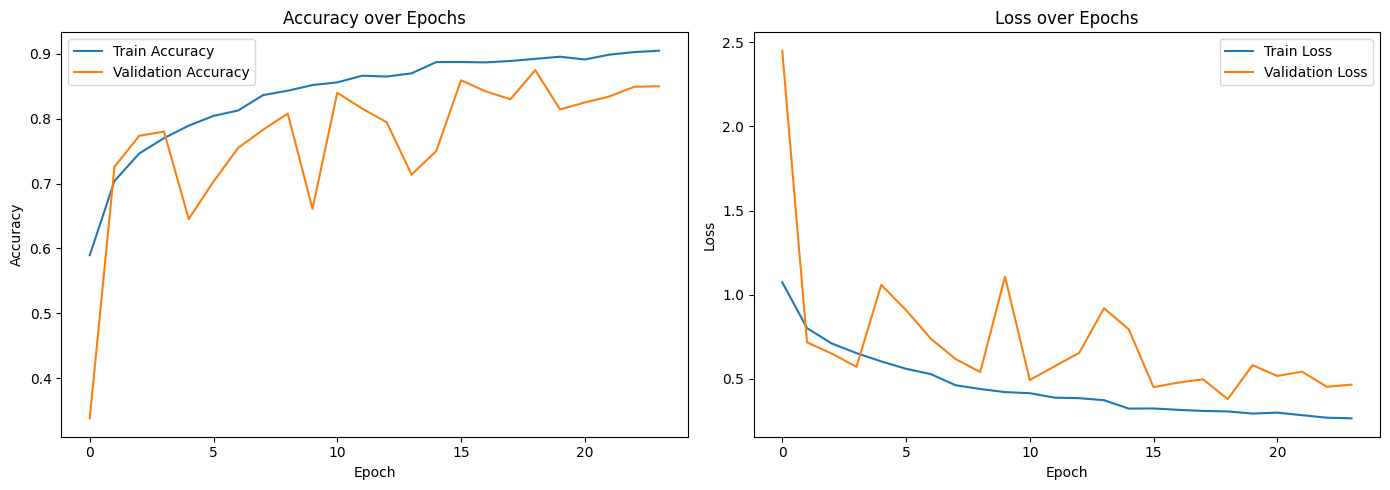

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], label='Train Accuracy')
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy')
axes[0].set_title('Accuracy over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(history.history['loss'], label='Train Loss')
axes[1].plot(history.history['val_loss'], label='Validation Loss')
axes[1].set_title('Loss over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150)
plt.show()

Evaluation on the Test Set (c.3)

Build Test dataset

In [ ]:
test_filepaths = []
test_labels = []

for class_idx, class_name in enumerate(classes):
    class_folder = os.path.join(test_dir, class_name)
    for fname in os.listdir(class_folder):
        test_filepaths.append(os.path.join(class_folder, fname))
        test_labels.append(class_idx)

test_filepaths = np.array(test_filepaths)
test_labels = np.array(test_labels)

test_ds = make_dataset(test_filepaths, test_labels, shuffle=False, augment=False)

print(f"Test set size: {len(test_filepaths)}")

Test set size: 3000


Get predictions

In [ ]:
y_pred_probs = model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_labels

print("Predictions shape:", y_pred_probs.shape)
print("Sample predicted classes:", y_pred[:10])
print("Sample true classes:     ", y_true[:10])

94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step
Predictions shape: (3000, 6)
Sample predicted classes: [0 0 0 5 0 0 0 0 0 0]
Sample true classes:      [0 0 0 0 0 0 0 0 0 0]


Overall and per class metrics

In [ ]:
from sklearn.metrics import classification_report, accuracy_score

overall_accuracy = accuracy_score(y_true, y_pred)
print(f"Overall Test Accuracy: {overall_accuracy:.4f}\n")

report = classification_report(y_true, y_pred, target_names=classes, digits=4)
print(report)

Overall Test Accuracy: 0.8690

              precision    recall  f1-score   support

   buildings     0.8465    0.8581    0.8523       437
      forest     0.9708    0.9831    0.9769       474
     glacier     0.8812    0.7649    0.8190       553
    mountain     0.8366    0.8095    0.8228       525
         sea     0.8231    0.9216    0.8696       510
      street     0.8649    0.8942    0.8793       501

    accuracy                         0.8690      3000
   macro avg     0.8705    0.8719    0.8700      3000
weighted avg     0.8699    0.8690    0.8681      3000



Save per-class metrics as a clean table

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=range(6))

metrics_df = pd.DataFrame({
    'Class': classes,
    'Precision': precision.round(4),
    'Recall': recall.round(4),
    'F1-Score': f1.round(4),
    'Support': support
})

print(metrics_df)
metrics_df.to_csv('per_class_metrics.csv', index=False)

       Class  Precision  Recall  F1-Score  Support
0  buildings     0.8465  0.8581    0.8523      437
1     forest     0.9708  0.9831    0.9769      474
2    glacier     0.8812  0.7649    0.8190      553
3   mountain     0.8366  0.8095    0.8228      525
4        sea     0.8231  0.9216    0.8696      510
5     street     0.8649  0.8942    0.8793      501


Confusion matrix (the key visual for c.3)

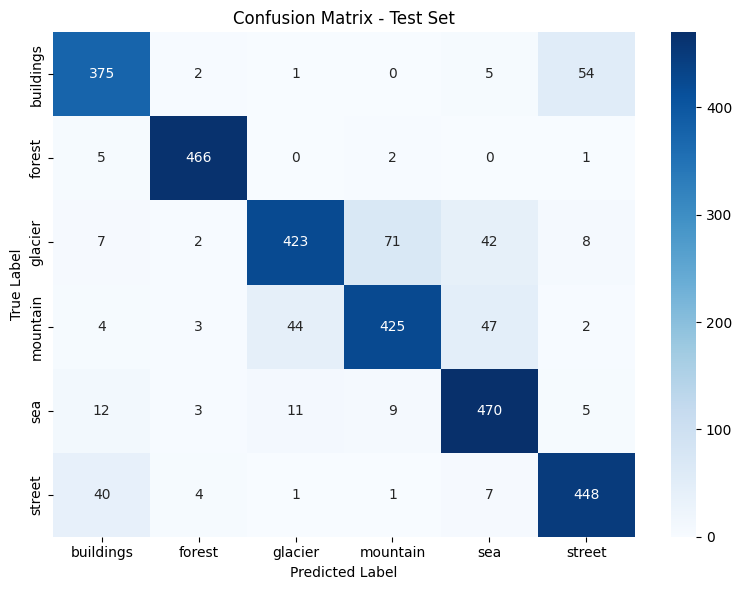

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Test Set')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

Misclassified examples (optional but strong differentiator)

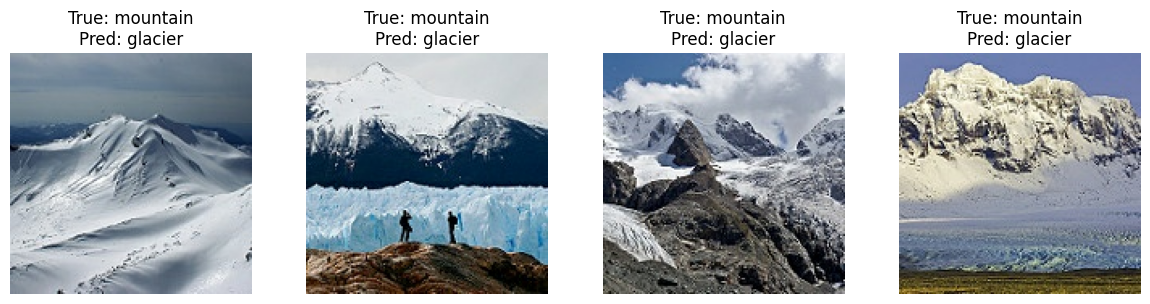

In [ ]:
misclassified_idx = np.where(y_pred != y_true)[0]

# grab a few examples: true=mountain, predicted=glacier specifically
mountain_as_glacier = [i for i in misclassified_idx if y_true[i] == 3 and y_pred[i] == 2][:4]

plt.figure(figsize=(12, 3))
for j, idx in enumerate(mountain_as_glacier):
    img = tf.io.read_file(test_filepaths[idx])
    img = tf.image.decode_jpeg(img, channels=3)
    plt.subplot(1, 4, j+1)
    plt.imshow(img)
    plt.title(f"True: mountain\nPred: glacier")
    plt.axis('off')
plt.tight_layout()
plt.savefig('misclassified_examples.png', dpi=150)
plt.show()

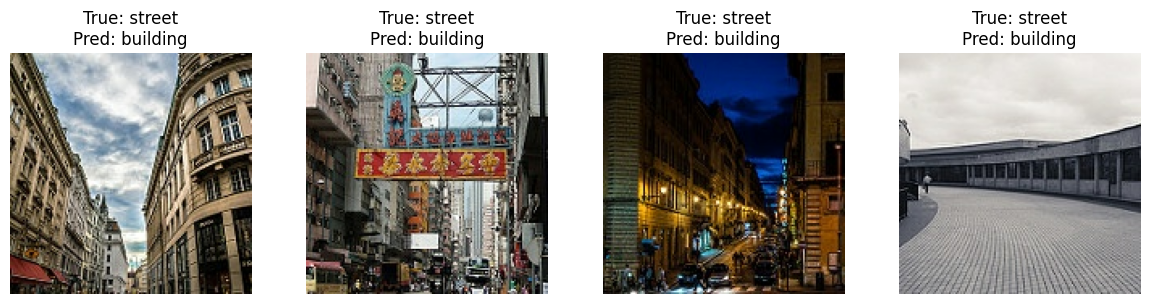

In [ ]:
import numpy as np

misclassified_idx = np.where(y_pred != y_true)[0]

# grab a few examples: true=street, predicted=building specifically
street_as_building = [i for i in misclassified_idx if y_true[i] == 5 and y_pred[i] == 0][:4]

plt.figure(figsize=(12, 3))
for j, idx in enumerate(street_as_building):
    img = tf.io.read_file(test_filepaths[idx])
    img = tf.image.decode_jpeg(img, channels=3)
    plt.subplot(1, 4, j+1)
    plt.imshow(img)
    plt.title(f"True: street\nPred: building")
    plt.axis('off')
plt.tight_layout()
plt.savefig('misclassified_street_as_building_examples.png', dpi=150)
plt.show()